In [7]:
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays, JSON
using Colors
using CSV
using DataFrames
using JuMP
import DataFrames
import HiGHS
import Plots
import StatsPlots
import Ipopt

In [ ]:

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load three training datasets
data1 = CSV.read("Location1.csv", DataFrame)   
data2 = CSV.read("Location2.csv", DataFrame)  
data3 = CSV.read("Location3.csv", DataFrame)  

data1.Time = DateTime.(data1.Time)  
data2.Time = DateTime.(data2.Time)  
data3.Time = DateTime.(data3.Time)  

# Combine training datasets
data = vcat(data1, data2, data3)  

n = nrow(data)  
sort_index = sortperm(data.Time)  

t = Float64.(data.Power[sort_index])

wind10_raw = Float64.(data.windspeed_10m[sort_index])
wind100_raw = Float64.(data.windspeed_100m[sort_index])
windgust_raw = Float64.(data.windgusts_10m[sort_index])  

time = data.Time[sort_index]

x = wind10_raw ./ 10.0
z = wind100_raw ./ 10.0
windgust = windgust_raw ./ 10.0  

hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

α = 0.01
iter_max = 25_000
λ = 0.01
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

function φ(x, j)
    return exp(-(γ * abs(x - c[j]))^2)
end

Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x[i], j)
    end
end

Random.seed!(128)
w_0 = rand()
w = rand(num_centers)

β_100 = rand()
β_windgust = rand()  

for iteration in 1:iter_max

    i = rand(1:n)
    ϕi = Φ[i, :]

    y_hat = w_0 +
            dot(ϕi, w) +
            β_100 * z[i] +
            β_windgust * windgust[i]  

    error = y_hat - t[i]

    w_0 -= α * error

    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end

    β_100 -= α * error * z[i]
    β_windgust -= α * error * windgust[i]  

    if reg_type == "l2"

        w .-= α * λ .* w
        β_100 -= α * λ * β_100
        β_windgust -= α * λ * β_windgust  

    elseif reg_type == "l1"

        w .= sign.(w) .* max.(0, abs.(w) .- α * λ)
        β_100 = sign(β_100) * max(0, abs(β_100) - α * λ)
        β_windgust = sign(β_windgust) * max(0, abs(β_windgust) - α * λ)

    end

end

function w̅(x_value, z_value, windgust_value)  

    return w_0 +
           sum(w[j] * φ(x_value, j) for j in 1:num_centers) +
           β_100 * z_value +
           β_windgust * windgust_value  

end

prediction = w_0 .+
             Φ * w .+
             β_100 .* z .+
             β_windgust .* windgust  

errors = prediction .- t

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("β_100 = ", β_100)
println("β_windgust = ", β_windgust)  
println("=======================================")


========== MODEL PERFORMANCE ==========
RMSE = 0.21613859159202997
MAE  = 0.1649111671777062
β_100 = 0.37000995237506024
β_windgust = 0.17825860205961466


In [4]:
function predict_24hr(filename)

    # Load forecast data
    forecast_data = CSV.read(filename, DataFrame)

    # Convert and sort by time
    forecast_data.Time = DateTime.(forecast_data.Time)
    sort_index = sortperm(forecast_data.Time)
    forecast_data = forecast_data[sort_index, :]

    # Take up to 24 hours
    n_24hr = min(24, nrow(forecast_data))

    time_24hr = forecast_data.Time[1:n_24hr]

    wind10_24hr = Float64.(
        forecast_data.windspeed_10m[1:n_24hr]
    )

    wind100_24hr = Float64.(
        forecast_data.windspeed_100m[1:n_24hr]
    )

    windgust_24hr = Float64.(
        forecast_data.windgusts_10m[1:n_24hr]
    )

    # Normalize exactly as during training
    x10_24hr = wind10_24hr ./ 10.0
    x100_24hr = wind100_24hr ./ 10.0
    xgust_24hr = windgust_24hr ./ 10.0

    # Generate power predictions
    power_prediction_24hr = [
        w̅(
            x10_24hr[i],
            x100_24hr[i],
            xgust_24hr[i]
        )
        for i in 1:n_24hr
    ]

    predictions = DataFrame(
        Time = time_24hr,
        windspeed_10m = wind10_24hr,
        windspeed_100m = wind100_24hr,
        windgusts_10m = windgust_24hr,
        PredictedPower = power_prediction_24hr
    )

    return predictions
end

predict_24hr (generic function with 1 method)

In [37]:
WindGenerator() = (
    variable_cost = 0.0,
)

wind_generator = WindGenerator()

generators = [
    (
        min = 0.0,
        max = 250.0,
        fixed_cost = 150.0,
        variable_cost = 1.0,
    ),
    (
        min = 0.0,
        max = 300.0,
        fixed_cost = 600.0,
        variable_cost = 1.0,
    ),
    (
        min = 0.0,
        max = 270.0,
        fixed_cost = 600.0,
        variable_cost = 1.0,
    )
]

function thermal_cost_function_1(g)
    return 0.11*g^2 + 5*g + 150
end

function thermal_cost_function_2(g)
    return 0.085*g^2 + 1.2*g + 600
end

function thermal_cost_function_3(g)
    return 0.1225*g^2 + g + 600
end

thermal_cost_functions = [
    thermal_cost_function_1,
    thermal_cost_function_2,
    thermal_cost_function_3
]

function extract_cost_coefficients(cost_function)
    c0 = cost_function(0.0)
    c1 = cost_function(1.0)
    c2 = cost_function(2.0)

    gamma = c0
    alpha = (c2 - 2c1 + c0) / 2
    beta = c1 - alpha - gamma

    return (alpha = alpha, beta = beta, gamma = gamma)
end

extract_cost_coefficients (generic function with 1 method)

In [38]:
function solve_nonlinear_economic_dispatch(
    generators::Vector,
    wind,
    scenario;
    silent::Bool = true,
)

    model = Model(Ipopt.Optimizer)

    if silent
        set_silent(model)
    end

    # Number of thermal generators
    N = 3

    @operator(model, op_tcf_1, 1, thermal_cost_function_1)
    @operator(model, op_tcf_2, 1, thermal_cost_function_2)
    @operator(model, op_tcf_3, 1, thermal_cost_function_3)

    coefficients = extract_cost_coefficients.(thermal_cost_functions)

    alpha_values = getproperty.(coefficients, :alpha)
    beta_values  = getproperty.(coefficients, :beta)

    @variable(
        model,
        generators[i].min <= g[i=1:N] <= generators[i].max
    )

    # All available wind power is sold
    @variable(model, w >= 0)
    @constraint(model, w == scenario.wind)

    @objective(
        model,
        Min,
        generators[1].variable_cost * op_tcf_1(g[1]) +
        generators[2].variable_cost * op_tcf_2(g[2]) +
        generators[3].variable_cost * op_tcf_3(g[3])
    )

    # Power balance
    @constraint(
        model,
        g[1] + g[2] + g[3] + w == scenario.demand
    )

    optimize!(model)
    assert_is_solved_and_feasible(model)

    g_value = value.(g)
    w_value = value(w)

    total_cost = objective_value(model)

    marginal_generator = nothing
    market_price = nothing

    # Check all three thermal generators
    for i in 1:N

        if (
            g_value[i] > generators[i].min + 1e-5 &&
            g_value[i] < generators[i].max - 1e-5
        )

            marginal_generator = i

            h = 1e-5

            marginal_factor =
                (
                    thermal_cost_functions[i](g_value[i] + h) -
                    thermal_cost_functions[i](g_value[i] - h)
                ) / (2h)

            market_price =
                generators[i].variable_cost *
                marginal_factor

            break
        end
    end

    if marginal_generator !== nothing
        alpha = alpha_values[marginal_generator]
        beta = beta_values[marginal_generator]
    end

    wind_revenue = market_price * w_value

    # Wind has zero production cost
    wind_cost = 0.0

    return (
        g = g_value,
        w = w_value,
        market_price = market_price,
        wind_revenue = wind_revenue,
        wind_cost = wind_cost,
        total_cost = total_cost,
        marginal_generator = marginal_generator,
        alpha = alpha,
        beta = beta
    )

end

solve_nonlinear_economic_dispatch (generic function with 1 method)

In [58]:
function solve_realtime_dispatch(
    projected_wind,
    wind_regulation,
    up_regulation_factor,
    down_regulation_factor,
    alpha,
    beta;
    silent::Bool = true,
)
    actual_wind = projected_wind + wind_regulation

    if wind_regulation > 0
        regulation_cost = up_regulation_factor * beta * wind_regulation
    elseif wind_regulation < 0
        regulation_cost = down_regulation_factor * beta * abs(wind_regulation)
    else
        regulation_cost = 0.0
    end

    cost = 0.5 * alpha * actual_wind^2 + regulation_cost

    return (
        actual_wind = actual_wind,
        regulation_cost = regulation_cost,
        c = cost,
    )
end

solve_realtime_dispatch (generic function with 1 method)

In [5]:
predictions = predict_24hr("Location4.csv")
forecast_power = predictions.PredictedPower

24-element Vector{Float64}:
 0.23277255525503537
 0.24978590761656233
 0.28253327385983873
 0.2756493039650205
 0.290032333941048
 0.2714444339308389
 0.273473414672219
 0.27473536418476596
 0.2507451092015629
 0.25459148543454724
 ⋮
 0.2224891069376475
 0.27880530515440666
 0.26718707983497214
 0.24650639063832244
 0.28038303544998977
 0.2050815914674789
 0.15554743924502656
 0.19695513399384124
 0.23728112379131433

In [ ]:
function Scenario(demand::Real, wind::Real)
    return (demand = demand, wind = wind)
end

day_ahead = Vector{Any}(undef, length(forecast_power))

for i in eachindex(forecast_power)
    power = forecast_power[i] * 50

    scenario = Scenario(600.0, power)

    day_ahead[i] = solve_nonlinear_economic_dispatch(
        generators,
        wind_generator,
        scenario
    )

    println(day_ahead[i])
end



(g = [172.2019642999968, 245.20254203518493, 170.95686590206657], w = 11.638627762751769, market_price = 42.88443219593319, wind_revenue = 499.1159431454338, wind_cost = 0.0, total_cost = 14628.876541438201, marginal_generator = 1, alpha = 0.10999999999998522, beta = 5.000000000000028)
(g = [171.93547083408544, 244.85766813812415, 170.71756564696227], w = 12.489295380828116, market_price = 42.82580362087174, wind_revenue = 534.8641113424054, wind_cost = 0.0, total_cost = 14592.421080401813, marginal_generator = 1, alpha = 0.10999999999998522, beta = 5.000000000000028)
(g = [171.4225231830762, 244.19385353093756, 170.2569595929944], w = 14.126663692991936, market_price = 42.71295510989148, wind_revenue = 603.3915521712984, wind_cost = 0.0, total_cost = 14522.391853936508, marginal_generator = 1, alpha = 0.10999999999998522, beta = 5.000000000000028)
(g = [171.53035219628396, 244.33339695979427, 170.35378564567085], w = 13.782465198251026, market_price = 42.736677460197825, wind_revenue 

In [60]:
for i in eachindex(forecast_power)

    real_time[i] = solve_realtime_dispatch(day_ahead[i].w, day_ahead[i].w*-0.1, 0.2, 0.4, day_ahead[i].alpha, day_ahead[i].beta)
    print(real_time[i])
end


(actual_wind = 10.474764986476591, regulation_cost = 2.3277255525503673, c = 8.362364136254932)(actual_wind = 11.240365842745305, regulation_cost = 2.4978590761656374, c = 9.44687941149625)(actual_wind = 12.713997323692743, regulation_cost = 2.8253327385984037, c = 11.71584777567485)(actual_wind = 12.404218678425924, regulation_cost = 2.7564930396502216, c = 11.219048295870666)(actual_wind = 13.05145502734716, regulation_cost = 2.9003233394104972, c = 12.269049647606838)(actual_wind = 12.21499952688775, regulation_cost = 2.714444339308405, c = 10.920786078610039)(actual_wind = 12.306303660249855, regulation_cost = 2.734734146722206, c = 11.06421518452643)(actual_wind = 12.363091388314468, regulation_cost = 2.747353641847676, c = 11.15388521901639)(actual_wind = 11.28352991407033, regulation_cost = 2.5074510920156436, c = 9.509943694709303)(actual_wind = 11.456616844554626, regulation_cost = 2.545914854345487, c = 9.76488867810582)(actual_wind = 15.27460729151061, regulation_cost = 3.39

In [26]:
data = CSV.read("Location4.csv", DataFrame)

data.Time = DateTime.(data.Time)
sort!(data, :Time)

# Extract first 24 hours
start_time = data.Time[1]
end_time = start_time + Hour(24)

first_24hr = data[
    (data.Time .>= start_time) .& (data.Time .< end_time),
    :
]

power_24hr = Float64.(first_24hr.Power)

# Store all real-time results
real_time = Vector{Any}(undef, length(power_24hr))

for i in eachindex(power_24hr)
    power = power_24hr[i] * 50

    scenario = Scenario(600.0, power)

    real_time[i] = solve_nonlinear_economic_dispatch(
        generators,
        wind_generator,
        scenario
    )
    println(real_time[i])
end

(g = [171.07530838663445, 243.7445167355436, 169.94517487782196], w = 15.235000000000001, market_price = 42.63656787770742, wind_revenue = 649.5681116168726, wind_cost = 0.0, total_cost = 14475.093866403444, marginal_generator = 1)
(g = [170.34067694624272, 242.7938172244509, 169.2855058293064], w = 17.580000000000002, market_price = 42.47494898663717, wind_revenue = 746.7096031850816, wind_cost = 0.0, total_cost = 14375.300612986839, marginal_generator = 1)
(g = [169.60604550585103, 241.84311771335814, 168.62583678079085], w = 19.925, market_price = 42.313330004617455, wind_revenue = 843.0931003420028, wind_cost = 0.0, total_cost = 14275.886355930332, marginal_generator = 1)
(g = [168.87141406545936, 240.89241820226533, 167.96616773227535], w = 22.27, market_price = 42.15171111354721, wind_revenue = 938.7186064986963, wind_cost = 0.0, total_cost = 14176.851095233924, marginal_generator = 1)
(g = [168.1383490034054, 239.94374576902123, 167.30790522757337], w = 24.610000000000003, marke

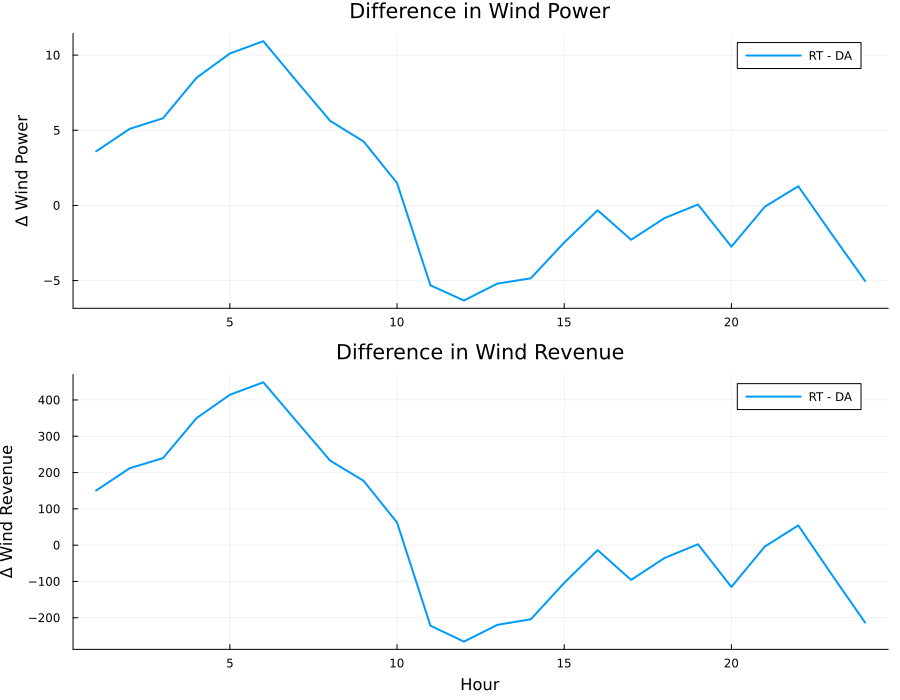

In [27]:
# Extract wind power
wind_da = [x.w for x in day_ahead]
wind_rt = [x.w for x in real_time]

# Extract wind revenue
revenue_da = [x.wind_revenue for x in day_ahead]
revenue_rt = [x.wind_revenue for x in real_time]

# Calculate differences: real-time - day-ahead
wind_difference = wind_rt .- wind_da
revenue_difference = revenue_rt .- revenue_da

n = min(length(wind_difference), length(revenue_difference))
time = 1:n

# Plot wind power difference
p1 = plot(time,wind_difference[1:n],lw = 2,xlabel = "",ylabel = "Δ Wind Power",label = "RT - DA",title = "Difference in Wind Power",hline = [0],grid = true)
# Plot wind revenue difference
p2 = plot(time,revenue_difference[1:n],lw = 2,xlabel = "Hour",ylabel = "Δ Wind Revenue",label = "RT - DA",title = "Difference in Wind Revenue",hline = [0],grid = true)

# Stack the plots
plot(p1, p2, layout = (2, 1), size = (900, 700))